In [1]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import pickle


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [3]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [4]:
file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# file_ids = [7]

In [5]:
filenames = list()
boms_spn = list()
hgms_spn = list()

path = os.path.join(read_utils.get_data_path(), 'brain')

for file_id in file_ids:
	filename = read_utils.get_filename(read_utils.get_filepath(path, file_id))
	filenames.append(filename)

	load_path = f'../../out/predictions/{filename}/bom/validation'
	bom_spn, _, _, _, _, _, _ = train_utils.load_predictions(load_path)
	boms_spn.append(bom_spn)

	load_path = f'../../out/predictions/{filename}/hgm/validation'
	hgm_spn, _, _, _, _, _, _ = train_utils.load_predictions(load_path)
	hgms_spn.append(hgm_spn)

In [6]:
neuron_scores = assemble(boms_spn, hgms_spn)

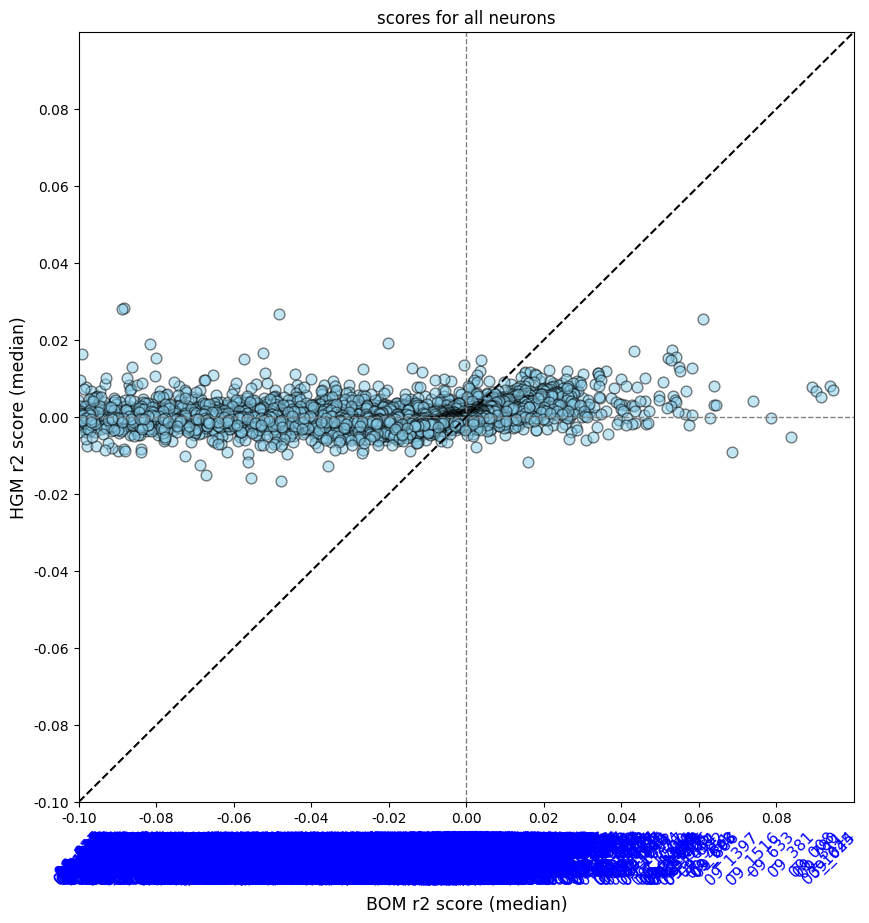

In [16]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=(-0.1, 0.1, -0.1, 0.1), force_medians=False
)

In [30]:
relevant_hgm_n = {key: value for key, value in neuron_scores.items() if 0 < value[0] < value[1]}

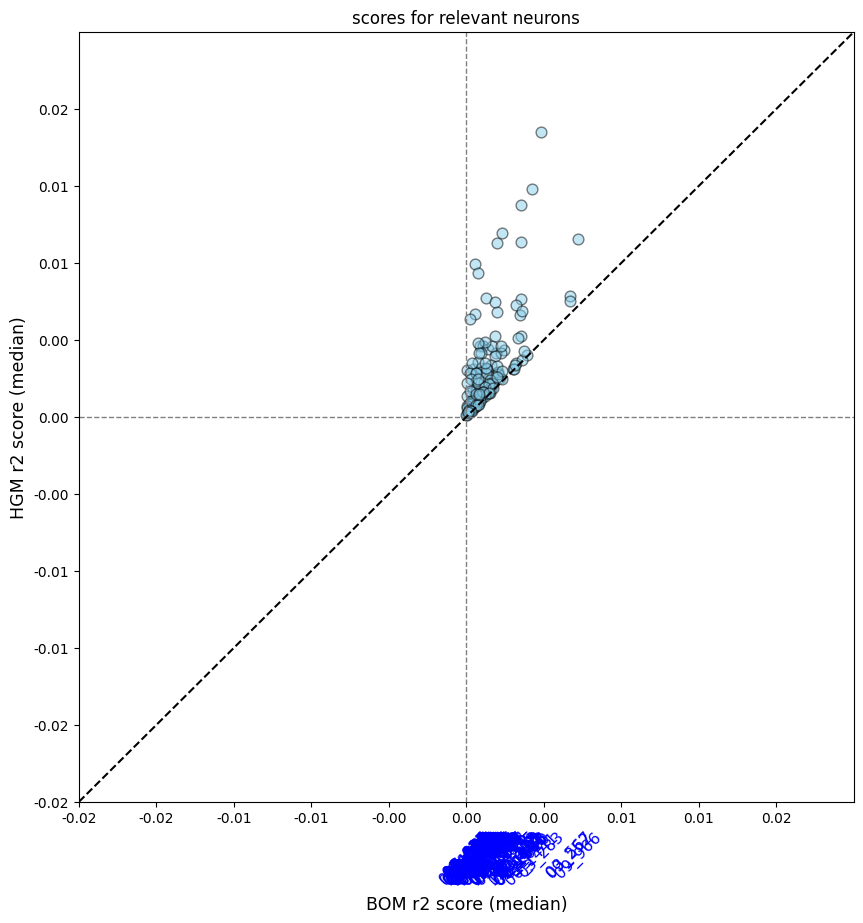

In [31]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n}, None,
	title='scores for relevant neurons', limits=(-0.02, 0.02, -0.02, 0.02), force_medians=False
)

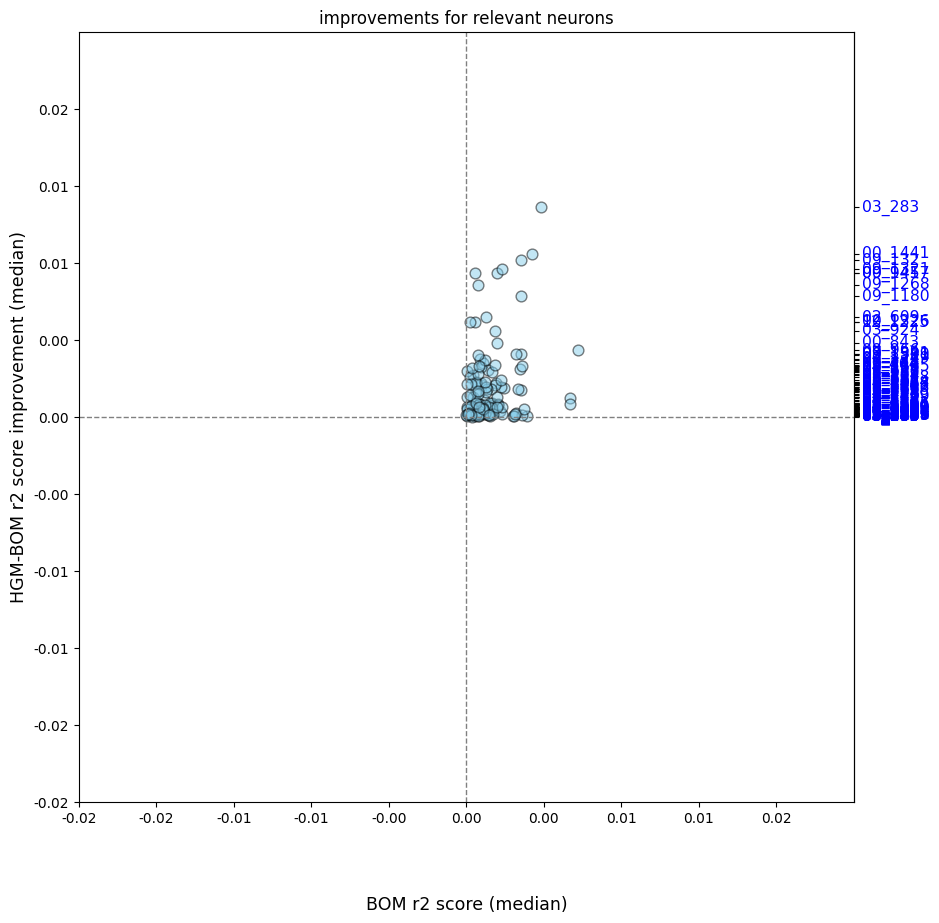

In [32]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n}, None,
	title='improvements for relevant neurons', limits=(-0.02, 0.02, -0.02, 0.02), force_medians=False
)

In [62]:
relevant_hgmimpr_n_keys = list([val[0] for val in reversed(sorted(relevant_hgm_n.items(), key=lambda x: np.median(x[1][1] - x[1][0])))])[:5]
print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in list(reversed(sorted(relevant_hgm_n.items(), key=lambda x: np.median(x[1][1] - x[1][0]))))[:5]]))

['03_283', '00_1441', '09_132', '09_1321', '09_941']
NEURON: 03_283,		IMPR: 0.0109
NEURON: 00_1441,		IMPR: 0.0085
NEURON: 09_132,		IMPR: 0.0081
NEURON: 09_1321,		IMPR: 0.0077
NEURON: 09_941,		IMPR: 0.0075


# single traces

In [33]:
file_id = 3

In [34]:
# read
path = os.path.join(read_utils.get_data_path(), 'brain')

(filename,
 traces,
 states, markers) = read_utils.get_data(path, file_id)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces.columns, traces.columns == ''))
])

In [35]:
load_path = f'../../out/predictions/{filename}/bom/full'
_, bom_man, bom_rec, bom_res, bom_pres, _, _ = train_utils.load_predictions(load_path)

load_path = f'../../out/predictions/{filename}/hgm/full'
_, hgm_man, hgm_rec, hgm_res, hgm_pres, _, _ = train_utils.load_predictions(load_path)

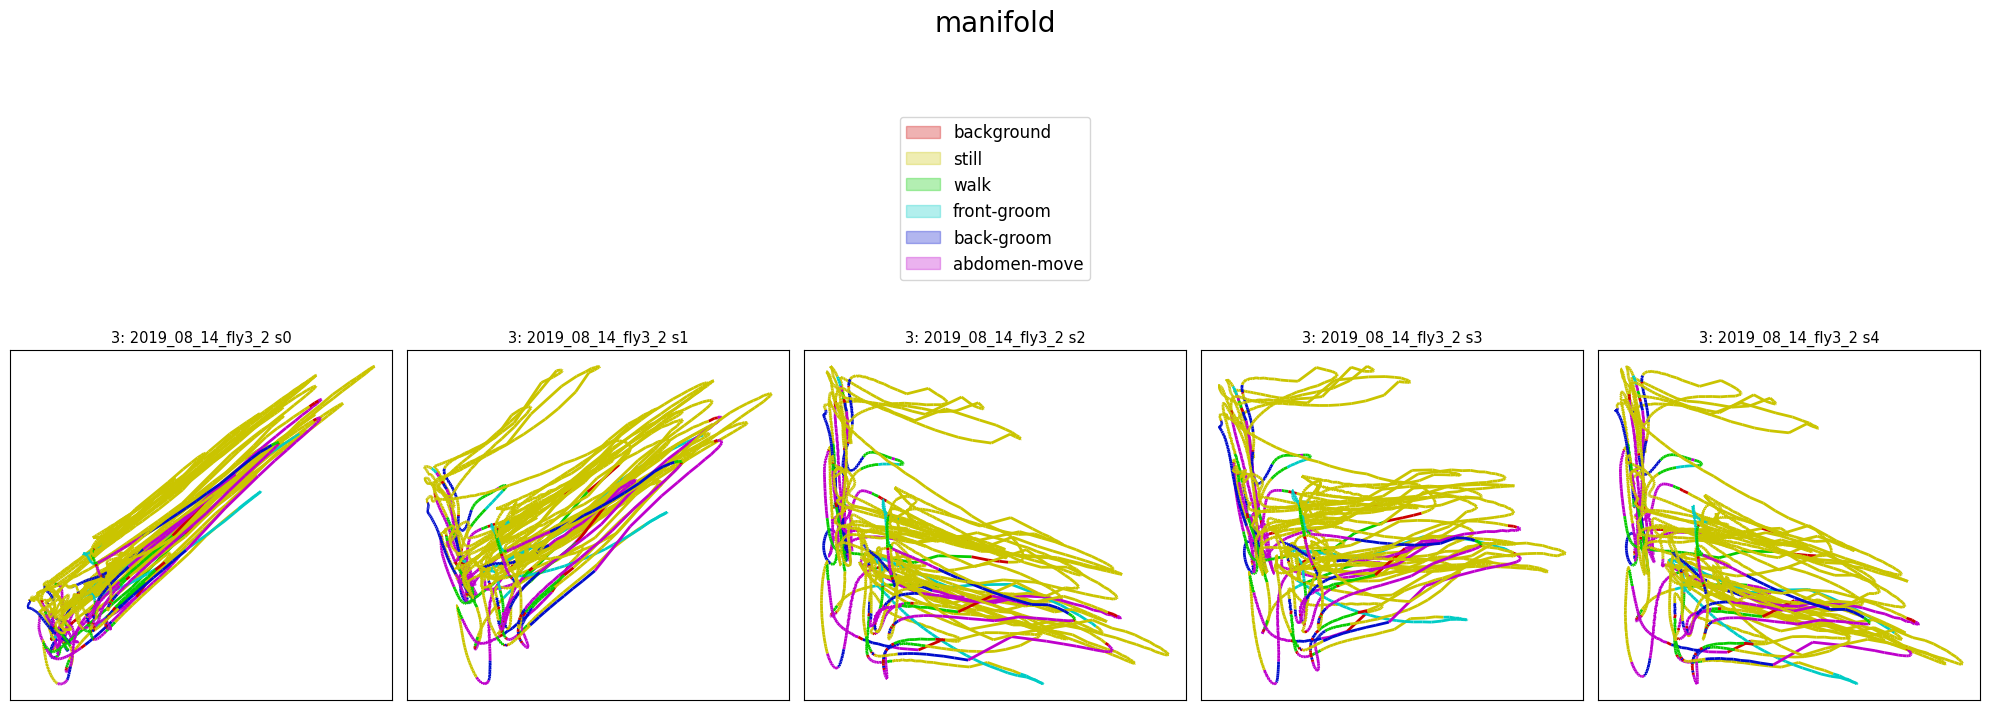

In [36]:
splits = 5
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
						  [hgm_man[s] for s in range(splits)],
						  [states for s in range(splits)],
						  None, None,
						  title='manifold', plots_per_row=splits, top_space=3.5,
						  save_path=None)

In [63]:
neurons = ['03_283']

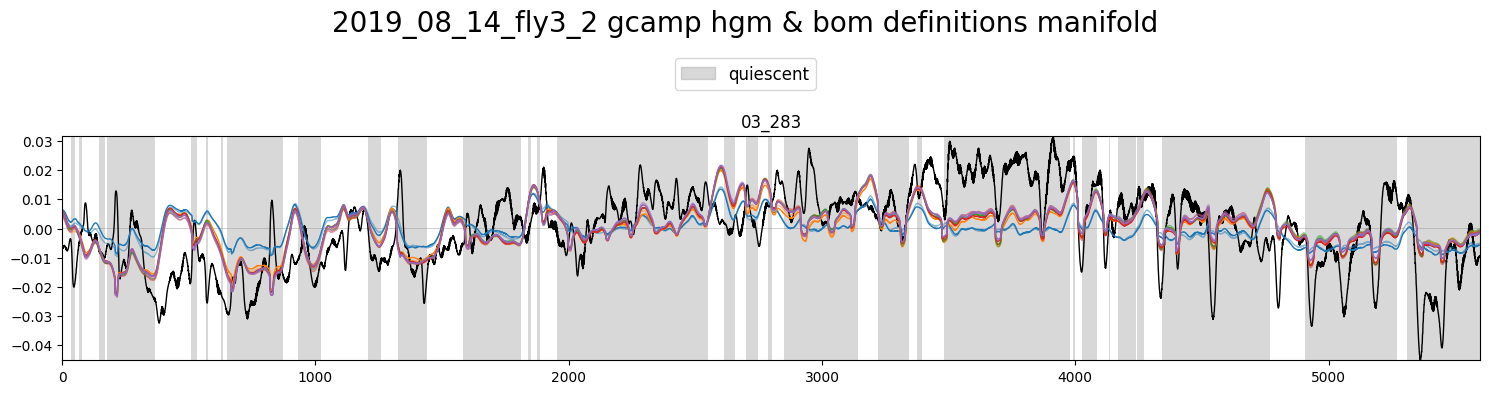

In [64]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_rec[i][neurons] for i in range(splits)],
	[bom_rec[i][neurons] for i in range(splits)],
	traces[neurons],
	states[['still']], label='quiescent',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

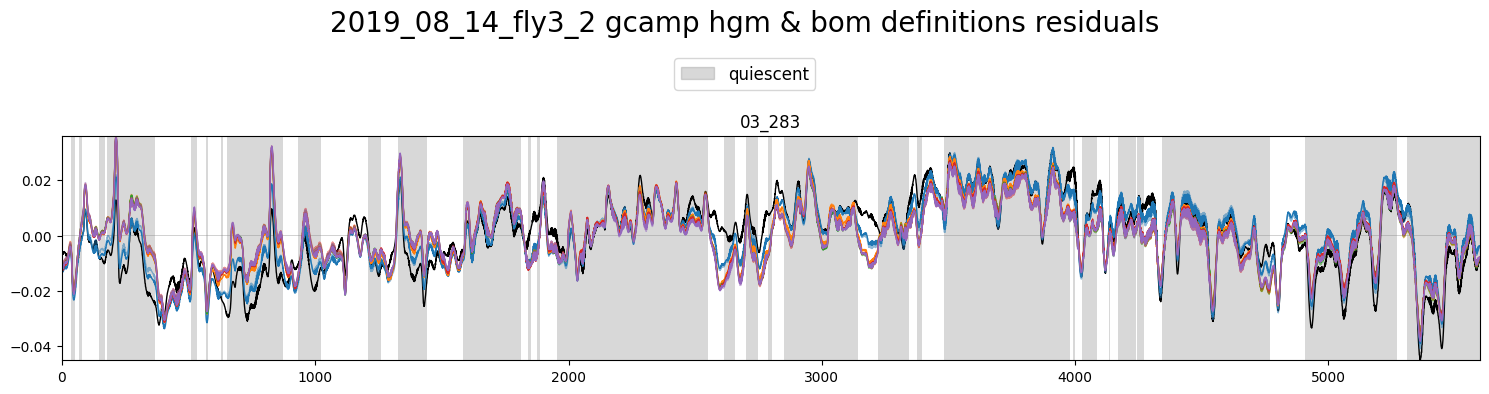

In [65]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_res[i][neurons] for i in range(splits)],
	[bom_res[i][neurons] for i in range(splits)],
	traces[neurons],
	states[['still']], label='quiescent',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

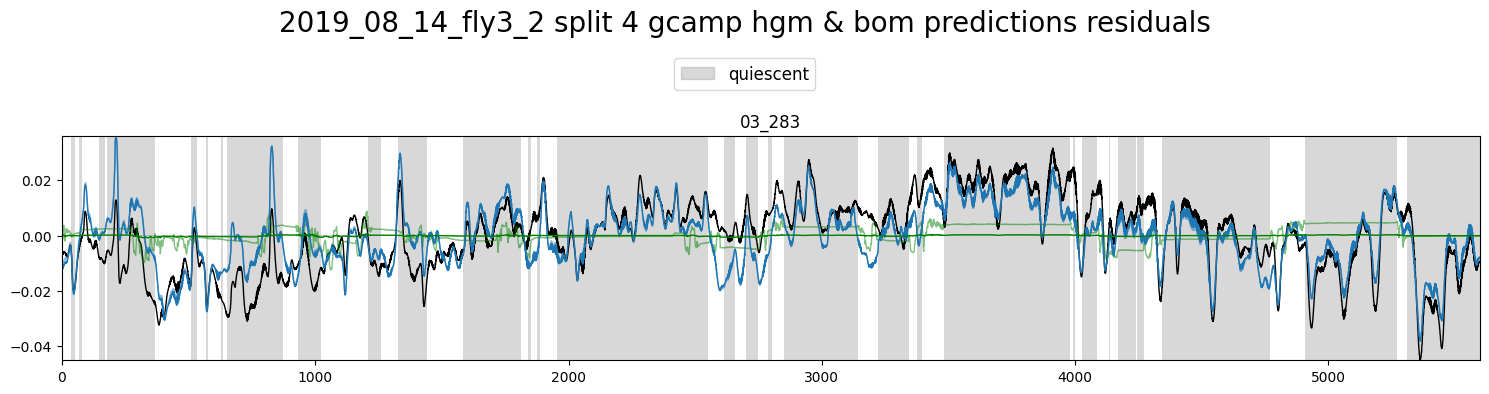

In [66]:
splits = 5
for i in range(splits):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res[i][neurons],
		 hgm_pres[i][neurons]],
		[bom_res[i][neurons],
		 bom_pres[i][neurons]],
		traces[neurons],
		states[['still']], label='quiescent',
		title=f'{filename} split {i} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'